# Challenge Ri Happy
## Tema e contexto

O desafio consiste em desenvolver e propor ao time da Ri Happy uma solução analítica capaz de prever o risco de desligamento voluntário de colaboradores operacionais das lojas nos primeiros 90 e 180 dias de empresa.

O tema do desafio consiste na aplicação de ciência de dados e Machine Learning a dados de recursos humanos do varejo, com foco em:

* Antecipação de desligamentos;
* Identificação de padrões e perfis de risco;
* Apoio estratégico à tomada de decisão em gestão de pessoas.


## Briefing

Leia o briefing abaixo. Ele simula o que você receberia de um gestor no mundo real. As perguntas são abertas de propósito.

> **De:** Marina Silva, Gerente de Operações  
> **Assunto:** Precisamos entender melhor o que está acontecendo com a satisfação dos clientes
>
> 1. **Satisfação por categoria:** Existem categorias onde a insatisfação é sistematicamente pior? Qual o tamanho de cada segmento?
> 2. **Relação entre frete e satisfação:** Pedidos com frete caro ou entrega atrasada geram mais avaliações negativas?
> 3. **Sazonalidade e tendência:** O volume tem sazonalidade? As notas pioram em picos?
>
> Preciso de diagnóstico visual para a diretoria. Se encontrarem inconsistências, documentem.

---
# Diagnóstico do Dataset

**Objetivo:** Conhecer os dados antes de tocar em qualquer coisa. Entender estrutura, volume, tipos, e identificar problemas.

In [1]:
# Importando as bibliotecas
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score
import joblib

In [2]:
# Carregamento do dataset
colaboradores = pd.read_excel('dados-colaboradores-v2.xlsx')

print(f'Colaboradores:  {colaboradores.shape[0]:,} linhas, {colaboradores.shape[1]} colunas')

Colaboradores:  11,071 linhas, 43 colunas


### 1.1 Visão geral das tabelas

Analise das primeiras linhas, e nomes das colunas.

In [3]:
# Primeiras linhas da tabela
print('=== COLABORADORES ===')
display(colaboradores.head())

=== COLABORADORES ===


,cod_funcionario,data_admissao,data_demissao,empresa,local,matricula,vinculo,cargo,codigo_gerente,uf,...,area_negocios,remuneracao_mensal,merito_recebido,promocoes_ultimos_6_meses,treinamentos_realizados,beneficios,nps_gestor,cod_loja_sap,faixa_grupo_faturamento,porte_funcionarios_loja
0,FUNC_000001,2024-07-15 00:00:00,NaN,RI HAPPY BRINQUEDOS S.A.,MANAIRA,MAT_100001,CLT,AUXILIAR DE ESTOQUE,GER_0101,PB,...,Vendas & Operações de Loja,"R$ 2.130,91",Não,Não,5 treinamentos,"Vale Transporte, Vale Refeição, Seguro de Vida...",60,1062,"G4 = Acima de R$ 14,500M",Porte GG (22+ func)
1,FUNC_000002,2024-07-15 00:00:00,NaN,RI HAPPY BRINQUEDOS S.A.,BOURBON IPIRANGA PO,MAT_100002,CLT,AUXILIAR DE ESTOQUE,GER_0102,RS,...,Vendas & Operações de Loja,"R$ 2.563,04",Sim,Não,4 treinamentos,"Vale Transporte, Vale Refeição, Seguro de Vida...",58,1305,"G1 = Até R$ 5,799M",Porte P (1 a 8 func)
2,FUNC_000003,2024-12-09 00:00:00,NaN,RI HAPPY BRINQUEDOS S.A.,PIRACICABA,MAT_100003,CLT,AUXILIAR DE LOJA,GER_0103,SP,...,Vendas & Operações de Loja,"R$ 2.399,00",Não,Não,1 treinamentos,"Vale Transporte, Vale Refeição, Seguro de Vida...",78,1008,"G2 = R$ 5,800M a R$ 8,999M",Porte M (9 a 14 func)
3,FUNC_000004,2024-12-09 00:00:00,NaN,RI HAPPY BRINQUEDOS S.A.,PIRACICABA,MAT_100004,CLT,AUXILIAR DE LOJA,GER_0103,SP,...,Vendas & Operações de Loja,"R$ 2.298,99",Não,Não,5 treinamentos,"Vale Transporte, Vale Refeição, Seguro de Vida...",78,1008,"G2 = R$ 5,800M a R$ 8,999M",Porte M (9 a 14 func)
4,FUNC_000005,2024-12-04 00:00:00,NaN,PBKIDS BRINQUEDOS LTDA,CIDADE JARDIM,MAT_100005,CLT,AUXILIAR DE LOJA,GER_0104,SP,...,Vendas & Operações de Loja,"R$ 1.967,01",Não,Não,4 treinamentos,"Vale Transporte, Vale Refeição, Seguro de Vida...",89,9005,Loja Não Inaugurada / Fechada,Sem Informação / Não Aplicável


In [4]:
print("=== COLABORADORES info====")
print(colaboradores.info())

=== COLABORADORES info====
<class 'pandas.DataFrame'>
RangeIndex: 11071 entries, 0 to 11070
Data columns (total 43 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   cod_funcionario                  11071 non-null  str    
 1   data_admissao                    11071 non-null  str    
 2   data_demissao                    7499 non-null   str    
 3   empresa                          11071 non-null  str    
 4   local                            11071 non-null  str    
 5   matricula                        11071 non-null  str    
 6   vinculo                          11071 non-null  str    
 7   cargo                            11071 non-null  str    
 8   codigo_gerente                   11071 non-null  str    
 9   uf                               11071 non-null  str    
 10  cidade                           11071 non-null  str    
 11  horas_trabalhadas                11071 non-null  int64  
 12  id

In [5]:
# Tipos de cada coluna
print('=== COLABORADORES dtypes ===')
print(colaboradores.dtypes)

=== COLABORADORES dtypes ===
cod_funcionario                        str
data_admissao                          str
data_demissao                          str
empresa                                str
local                                  str
matricula                              str
vinculo                                str
cargo                                  str
codigo_gerente                         str
uf                                     str
cidade                                 str
horas_trabalhadas                    int64
id_regional                            str
superintendente                        str
codigo_flexivel_centro_de_custo        str
grupo_de_cargos                        str
bairro                                 str
func_sts_sexo                          str
dt_func_dat_nasc                       str
ccu_nom                                str
func_sts_dem                           str
desc_motivo_rescisao                   str
desc_tipo_cargo          

In [6]:
# Conversao de tipos

# 1. Função para arrumar a distâncias que está como data no Excel
def corrigir_distancia(valor):
    if pd.isna(valor):
        return pd.NA
    
    # Se o Excel transformou em data (ex: 7,4 virou 07/01/1900 09:36)
    if isinstance(valor, datetime.datetime):
        # O Excel baseia seu calendário no dia 31/12/1899. Calculamos a diferença de dias para reverter:
        diferenca = valor - datetime.datetime(1899, 12, 31)
        return diferenca.total_seconds() / 86400.0  # 86400 são os segundos de um dia
    
    # Se já for número ou texto, tenta converter normalmente
    try:
        texto = str(valor).replace(',', '.')
        return float(texto)
    except:
        return pd.NA

# 1. nu_horas_base: de float64 para int64
colaboradores['nu_horas_base'] = pd.to_numeric(colaboradores['nu_horas_base'], errors='coerce').astype('Int64')

# 2. distancia_loja_casa_km: de object para float64
colaboradores['distancia_loja_casa_km'] = colaboradores['distancia_loja_casa_km'].apply(corrigir_distancia)

# 3. resultado_raciocinio_logico: forçado para número (protegido contra textos/sujeira do Excel)
colaboradores['resultado_raciocinio_logico'] = pd.to_numeric(colaboradores['resultado_raciocinio_logico'], errors='coerce')

# 4. remuneracao_mensal: de string ("R$ 2.130,91") para float64
texto_remuneracao = (
    colaboradores['remuneracao_mensal']
    .astype(str)
    .str.replace('R$', '', regex=False)
    .str.strip()
    .str.replace('.', '', regex=False)   # Remove o ponto de milhares
    .str.replace(',', '.', regex=False)  # Troca a vírgula dos centavos por ponto
)
colaboradores['remuneracao_mensal'] = pd.to_numeric(texto_remuneracao, errors='coerce')

# 5. treinamentos_realizados
colaboradores['treinamentos_realizados'] = (
    colaboradores['treinamentos_realizados']
    .astype(str)
    .str.extract(r'(\d+)', expand=False)
    .astype('Int64')
)

# 6. ultima_avaliacao_performance: forçado para número (protegido contra textos/sujeira do Excel)
colaboradores['ultima_avaliacao_performance'] = pd.to_numeric(colaboradores['ultima_avaliacao_performance'], errors='coerce')

print(colaboradores.dtypes)

cod_funcionario                        str
data_admissao                          str
data_demissao                          str
empresa                                str
local                                  str
matricula                              str
vinculo                                str
cargo                                  str
codigo_gerente                         str
uf                                     str
cidade                                 str
horas_trabalhadas                    int64
id_regional                            str
superintendente                        str
codigo_flexivel_centro_de_custo        str
grupo_de_cargos                        str
bairro                                 str
func_sts_sexo                          str
dt_func_dat_nasc                       str
ccu_nom                                str
func_sts_dem                           str
desc_motivo_rescisao                   str
desc_tipo_cargo                        str
modelo_cont

### 1.2 Investigando `colaboradores` das lojas
#### Aqui a análise passa a se filtrar apenas nos colaboradores da área de negócios `Vendas & Operações de Loja`

In [7]:
# Datasets com desligamentos para colaboradores das lojas
colaboradores_vendas = colaboradores[colaboradores['area_negocios'] == 'Vendas & Operações de Loja']

### 1.2.1 Duplicatas em `colaboradores` das lojas

In [8]:
# Verificação de duplicatas nos colaboradores das lojas
print(f'Duplicatas exatas em colaboradores das lojas: {colaboradores_vendas.duplicated().sum()}')
print(f'Funcionários duplicados: {colaboradores_vendas["cod_funcionario"].duplicated().sum()}')


Duplicatas exatas em colaboradores das lojas: 0
Funcionários duplicados: 0


### 1.2.2 Missings em `colaboradores` das lojas

In [9]:
# Calcula os indicadores (usando a base filtrada)
total_linhas = len(colaboradores_vendas)
ausentes = colaboradores_vendas.isnull().sum()
percentual = (ausentes / total_linhas) * 100

# Montagem da tabela
tabela_missings = pd.DataFrame({
    'Total_Valores': total_linhas,
    'Valores_Ausentes': ausentes,
    'Percentual_(%)': percentual.round(2)
})

# Nomeando índice
tabela_missings.index.name = 'Colunas'
tabela_missings = tabela_missings.reset_index()

# Filtra apenas colunas com ausentes e ordena da maior para a menor quantidade
tabela_missings = tabela_missings[tabela_missings['Valores_Ausentes'] > 0].sort_values(by='Valores_Ausentes', ascending=False)

# Imprime o resultado
if len(tabela_missings) > 0:
    print('=== COLABORADORES (VENDAS & OPERAÇÕES DE LOJA) - Valores ausentes ===')
    # Use to_string(index=False) para esconder o número da linha na hora de imprimir
    print(tabela_missings.to_string(index=False)) 
else:
    print('=== COLABORADORES (VENDAS & OPERAÇÕES DE LOJA) - Sem valores ausentes ===')

# Resumo rápido
print('\n--- Resumo de missings na tabela (Vendas & Operações de Loja) ---')
total_missing_geral = colaboradores_vendas.isnull().sum().sum()
print(f' colaboradores_vendas: {total_missing_geral} valores ausentes no total')

=== COLABORADORES (VENDAS & OPERAÇÕES DE LOJA) - Valores ausentes ===
                     Colunas  Total_Valores  Valores_Ausentes  Percentual_(%)
ultima_avaliacao_performance          10421              9323           89.46
                      bairro          10421              8039           77.14
               nu_horas_base          10421              8038           77.13
                     ccu_nom          10421              8038           77.13
             modelo_contrato          10421              8038           77.13
             desc_tipo_cargo          10421              8038           77.13
               data_demissao          10421              3246           31.15
                func_sts_dem          10421              3246           31.15
        desc_motivo_rescisao          10421              3246           31.15
 resultado_raciocinio_logico          10421              1246           11.96

--- Resumo de missings na tabela (Vendas & Operações de Loja) ---
 cola

#### Percepções após análise de missings:
Os 3246 dados ausentes nas colunas `data_demissao`, `desc_motivo_rescisao` e `func_sts_dem` são os colaboradores que hoje estão ativos na companhia.
Os dados ausentes nas colunas `bairro`, `ccu_nom`, `modelo_contrato`, `desc_tipo_cargo`, `nu_horas_base` poderiam ser preenchidos com dados que hoje já fazem parte do contrato Ri Happy colaborador. Necessário verificar com o RH essa inserção no sistema.
Colaboradores com admissões recentes distribuidos por diferentes meses sem resultado de raciocinio lógico. Aqui não foram colaboradores que entraram antes da Ri Happy inserir essa análise na admissão ou colaboradores de extra natal.
Os ausentes na coluna `ultima_avaliacao_performance` são de colaborados dos períodos de 2002 a 2026, o que leva a entender que não são colaboradores recentes na companhia.

#### Premissas para o algoritmo de ML:
Inicialmente foi pensando em preencher as colunas `resultado_raciocinio_logico` e `ultima_avaliacao_performance` com a mediana do cargo, porém existem cargos com apenas um único colaborador. O que nos levou a modificar a premissa.
Para os missings na coluna de `ultima_avaliacao_performance` que correspondem a temporários, estagiários e aprendizes, optou-se por preencher os valores com 0.
Algoritmos baseados em árvores (Random Forest e XGBoost) lidarão com esse 0 criando uma regra de corte combinada com a coluna vinculo. O modelo aprenderá a isolar esse grupo de forma estrutural, entendendo que a ausência de nota é uma característica do contrato e não um indicativo de má performance.

Para a coluna `resultado_raciocinio_logico` Utilizou-se a premissa de Unificação Semântica (De-Para). Esses cargos foram aglutinados em cargos "irmãos" de maior volumetria que exigem o mesmo nível cognitivo e de responsabilidade operacional. Isso resolve a ausência da nota por herança da mediana do novo grupo consolidado.
REPOSITOR e OPERADOR DE ESTOQUE: Receberá a mediana de ESTOQUISTA. A natureza operacional e o nível cognitivo exigido tendem a ser equivalentes.
GERENTE ASSISTENTE: Receberá a mediana de GERENTE DE LOJA I.
COORDENADOR COMERCIAL e COORDENADOR EXPANSAO: Receberá a mediana de SUPERVISOR DE LOJA.
Para a coluna `ultima_avaliacao_performance` também será criada uma coluna `sem_avaliacao_formal` com valor binário: 1 (Sim) e 0 (Não).

In [10]:
# Tabela com contagem de colaboradores e medianas das colunas de interesse
mediana_por_cargo = (
    colaboradores_vendas.groupby('cargo').agg(
        quantidade_colaboradores=('cod_funcionario', 'count'),
        resultado_raciocinio_logico=('resultado_raciocinio_logico', 'median'),
        ultima_avaliacao_performance=('ultima_avaliacao_performance', 'median')
    )
    .reset_index()
    .sort_values(by='resultado_raciocinio_logico', ascending=False)
)

# Exibe a tabela completa
display(mediana_por_cargo)

,cargo,quantidade_colaboradores,resultado_raciocinio_logico,ultima_avaliacao_performance
4,ANALISTA FRANQUIAS SR,1,97.0,NaN
1,ANALISTA COMERCIAL PL,1,91.0,NaN
7,ANALISTA INTELIGENCIA DE OPERACOES SR,1,91.0,NaN
6,ANALISTA IMPORTACAO SR,1,86.0,NaN
15,ASSISTENTE LOGISTICA,1,85.0,NaN
39,GERENTE DE LOJA II,11,85.0,46.0
40,GERENTE DE LOJA III,2,85.0,74.0
41,GERENTE DE LOJA IV,15,84.0,64.0
35,GERENTE DE LOJA 1,44,82.0,76.0
22,CAIXA SR,6,81.0,NaN


#### Os cargos de Gerente que hoje estão em com numeral serão substituidos com a nomenclatura de algarismo romano de forma a unificar para utilização no algoritmo de ML.

In [11]:
# Dicionário de padronização: Numerais Arábicos para Romanos (Apenas Gerentes)
correcoes_gerentes = {
    'GERENTE DE LOJA 1': 'GERENTE DE LOJA I',
    'GERENTE DE LOJA 2': 'GERENTE DE LOJA II',
    'GERENTE DE LOJA 3': 'GERENTE DE LOJA III'
}
# Aplicando a padronização na base
colaboradores_vendas['cargo'] = colaboradores_vendas['cargo'].replace(correcoes_gerentes)

In [12]:
# Tabela com contagem de colaboradores e medianas das colunas de interesse
mediana_por_cargo = (
    colaboradores_vendas.groupby('cargo')
    .agg(
        quantidade_colaboradores=('cod_funcionario', 'count'),
        resultado_raciocinio_logico=('resultado_raciocinio_logico', 'median'),
        ultima_avaliacao_performance=('ultima_avaliacao_performance', 'median')
    )
    .reset_index()
    .sort_values(by='resultado_raciocinio_logico', ascending=False)
)

# Exibe a tabela completa
display(mediana_por_cargo)

,cargo,quantidade_colaboradores,resultado_raciocinio_logico,ultima_avaliacao_performance
4,ANALISTA FRANQUIAS SR,1,97.0,NaN
1,ANALISTA COMERCIAL PL,1,91.0,NaN
7,ANALISTA INTELIGENCIA DE OPERACOES SR,1,91.0,NaN
6,ANALISTA IMPORTACAO SR,1,86.0,NaN
15,ASSISTENTE LOGISTICA,1,85.0,NaN
38,GERENTE DE LOJA IV,15,84.0,64.0
35,GERENTE DE LOJA I,57,81.0,76.0
22,CAIXA SR,6,81.0,NaN
39,GERENTE DE LOJA V,8,81.0,83.0
5,ANALISTA IMPORTACAO JR,2,80.5,NaN


In [13]:
# Conversão da coluna para Float64 para aceitar as medianas decimais (como 62.5)
colaboradores_vendas['resultado_raciocinio_logico'] = colaboradores_vendas['resultado_raciocinio_logico'].astype('Float64')

# Calculo das medianas dos cargos de referência
mediana_estoquista = colaboradores_vendas[colaboradores_vendas['cargo'] == 'ESTOQUISTA']['resultado_raciocinio_logico'].median()
mediana_gerente_i = colaboradores_vendas[colaboradores_vendas['cargo'] == 'GERENTE DE LOJA I']['resultado_raciocinio_logico'].median()
mediana_supervisor = colaboradores_vendas[colaboradores_vendas['cargo'] == 'SUPERVISOR DE LOJA']['resultado_raciocinio_logico'].median()

# Criação do dicionário de mapeamento das regras
mapa_imputacao_direcionada = {
    'REPOSITOR': mediana_estoquista,
    'OPERADOR DE ESTOQUE': mediana_estoquista,
    'GERENTE ASSISTENTE': mediana_gerente_i,
    'COORDENADOR COMERCIAL': mediana_supervisor,
    'COORDENADOR EXPANSAO': mediana_supervisor
}

# Aplica o preenchimento apenas para esses 5 cargos
for cargo_alvo, valor_mediana in mapa_imputacao_direcionada.items():
    mascara = colaboradores_vendas['cargo'] == cargo_alvo
    colaboradores_vendas.loc[mascara, 'resultado_raciocinio_logico'] = colaboradores_vendas.loc[mascara, 'resultado_raciocinio_logico'].fillna(valor_mediana)

# Preenche TODOS OS RESTANTES (os 11% gerais) com a mediana do seu próprio cargo
colaboradores_vendas['resultado_raciocinio_logico'] = colaboradores_vendas.groupby('cargo')['resultado_raciocinio_logico'].transform(lambda x: x.fillna(x.median()))

# Validação Final
nulos_restantes = colaboradores_vendas['resultado_raciocinio_logico'].isnull().sum()
print(f"Total de valores nulos em 'resultado_raciocinio_logico' agora: {nulos_restantes}")

Total de valores nulos em 'resultado_raciocinio_logico' agora: 0


In [14]:
# Cria a Flag: Se a nota for nula (isnull), recebe 1. Se tiver nota, recebe 0.
colaboradores_vendas['sem_avaliacao_formal'] = colaboradores_vendas['ultima_avaliacao_performance'].isnull().astype(int)

# Substitui os valores nulos (NaN) da avaliação de performance por 0
colaboradores_vendas['ultima_avaliacao_performance'] = colaboradores_vendas['ultima_avaliacao_performance'].fillna(0)

# Validação do preenchimento
nulos_restantes_performance = colaboradores_vendas['ultima_avaliacao_performance'].isnull().sum()
print(f"Total de valores nulos em 'ultima_avaliacao_performance' agora: {nulos_restantes_performance}")

# Validação da nova coluna (Flag)
print("\nDistribuição da nova flag 'sem_avaliacao_formal':")
print(colaboradores_vendas['sem_avaliacao_formal'].value_counts())

Total de valores nulos em 'ultima_avaliacao_performance' agora: 0

Distribuição da nova flag 'sem_avaliacao_formal':
sem_avaliacao_formal
1    9323
0    1098
Name: count, dtype: int64


#### Analisamos a sequência de duplicatas, missings e estatísticas descritivas.

---

### 1.3 Investigação dos colaboradores

Agora será feita uma estatística descritiva para ver como estão os dados. 

In [15]:
# Estatística descritiva dos colaboradores
colab_vendas_describe = colaboradores_vendas.describe()
display(colab_vendas_describe)
# Nada visto como extremamente anormal nos dados.

,horas_trabalhadas,nu_horas_base,ultima_avaliacao_performance,qtd_filhos,distancia_loja_casa_km,resultado_raciocinio_logico,remuneracao_mensal,treinamentos_realizados,nps_gestor,sem_avaliacao_formal
count,10421.000000,2383.0,10421.000000,10421.000000,10421.000000,10421.0,10421.000000,10421.0,10421.000000,10421.000000
mean,217.026197,216.412086,7.522311,0.844737,8.466021,69.444295,2672.230704,3.035793,62.488821,0.894636
std,14.697010,16.026627,22.471133,1.006923,8.426575,11.907676,1335.438997,1.988297,21.513898,0.307037
min,80.000000,80.0,0.000000,0.000000,1.100000,30.0,901.170000,0.0,0.000000,0.000000
25%,220.000000,220.0,0.000000,0.000000,3.000000,62.0,2135.390000,1.0,49.000000,1.000000
50%,220.000000,220.0,0.000000,1.000000,5.100000,69.0,2397.480000,3.0,62.000000,1.000000
75%,220.000000,220.0,0.000000,2.000000,11.000000,77.0,2766.320000,5.0,79.000000,1.000000
max,220.000000,220.0,100.000000,4.000000,31.120000,100.0,13443.030000,8.0,100.000000,1.000000


Verificação dos valores únicos das colunas de texto

In [16]:
# Seleciona apenas as colunas que são de texto (object)
colunas_texto = colaboradores_vendas.select_dtypes(include=['object']).columns

print("--- RAIO-X DE TODAS AS COLUNAS DE TEXTO ---\n")

for coluna in colunas_texto:
    print(f"[{coluna.upper()}]")
    print(colaboradores_vendas[coluna].value_counts(dropna=False))
    print("-" * 40 + "\n")

--- RAIO-X DE TODAS AS COLUNAS DE TEXTO ---

[COD_FUNCIONARIO]
cod_funcionario
FUNC_000001    1
FUNC_000002    1
FUNC_000003    1
FUNC_000004    1
FUNC_000005    1
              ..
FUNC_011067    1
FUNC_011068    1
FUNC_011069    1
FUNC_011070    1
FUNC_011071    1
Name: count, Length: 10421, dtype: int64
----------------------------------------

[DATA_ADMISSAO]
data_admissao
2024-10-02 00:00:00    1645
2024-12-09 00:00:00    1275
2025-10-01 00:00:00     796
2024-12-02 00:00:00     286
2024-11-21 00:00:00     107
                       ... 
2009-10-28 00:00:00       1
2013-10-07 00:00:00       1
2021-03-15 00:00:00       1
2011-11-07 00:00:00       1
2021-12-17 00:00:00       1
Name: count, Length: 1373, dtype: int64
----------------------------------------

[DATA_DEMISSAO]
data_demissao
NaN                    3246
2024-12-24 00:00:00    1264
2024-10-15 00:00:00    1227
2025-12-24 00:00:00     651
2025-01-02 00:00:00     365
                       ... 
2025-02-23 00:00:00       1
2025-

/tmp/ipykernel_199570/3145542522.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_texto = colaboradores_vendas.select_dtypes(include=['object']).columns


Visando dar um impacto mais legível para os gráficos alguns dados serão encurtados nas colunas `faixa_grupo_faturamento` e `porte_funcionarios_loja`

In [17]:
# Dicionário para encurtar os textos de Faturamento
mapa_faturamento = {
    'G1 = Até R$ 5,799M': 'G1',
    'G2 = R$ 5,800M a R$ 8,999M': 'G2',
    'G3 = R$ 9,000M a R$ 14,500M': 'G3',
    'G4 = Acima de R$ 14,500M': 'G4',
    'Loja Não Inaugurada / Fechada': 'Fechada/Inativa',
    'Não Classificado': 'Sem_Info_Fat',
    'Não Aplicável (Corporativo)': 'Corporativo'
}

# Dicionário para encurtar os textos de Porte da Loja
mapa_porte = {
    'Porte P (1 a 8 func)': 'Porte_P',
    'Porte M (9 a 14 func)': 'Porte_M',
    'Porte G (15 a 21 func)': 'Porte_G',
    'Porte GG (22+ func)': 'Porte_GG',
    'Sem Informação / Não Aplicável': 'Sem_Info_Porte',
    'Corporativo / Controlada': 'Corporativo',
    'Corporativo / Matriz': 'Corporativo'
}

# Aplicar a substituição na base de lojas
colaboradores_vendas['faixa_grupo_faturamento'] = colaboradores_vendas['faixa_grupo_faturamento'].replace(mapa_faturamento)
colaboradores_vendas['porte_funcionarios_loja'] = colaboradores_vendas['porte_funcionarios_loja'].replace(mapa_porte)

# Validação rápida para ver como ficou
print(colaboradores_vendas['faixa_grupo_faturamento'].value_counts())
print("-" * 30)
print(colaboradores_vendas['porte_funcionarios_loja'].value_counts())

faixa_grupo_faturamento
G3                 2810
G2                 2721
G1                 2590
G4                 2100
Fechada/Inativa     174
Corporativo          19
Sem_Info_Fat          7
Name: count, dtype: int64
------------------------------
porte_funcionarios_loja
Porte_M           4096
Porte_G           2749
Porte_P           1929
Porte_GG          1432
Sem_Info_Porte     196
Corporativo         19
Name: count, dtype: int64


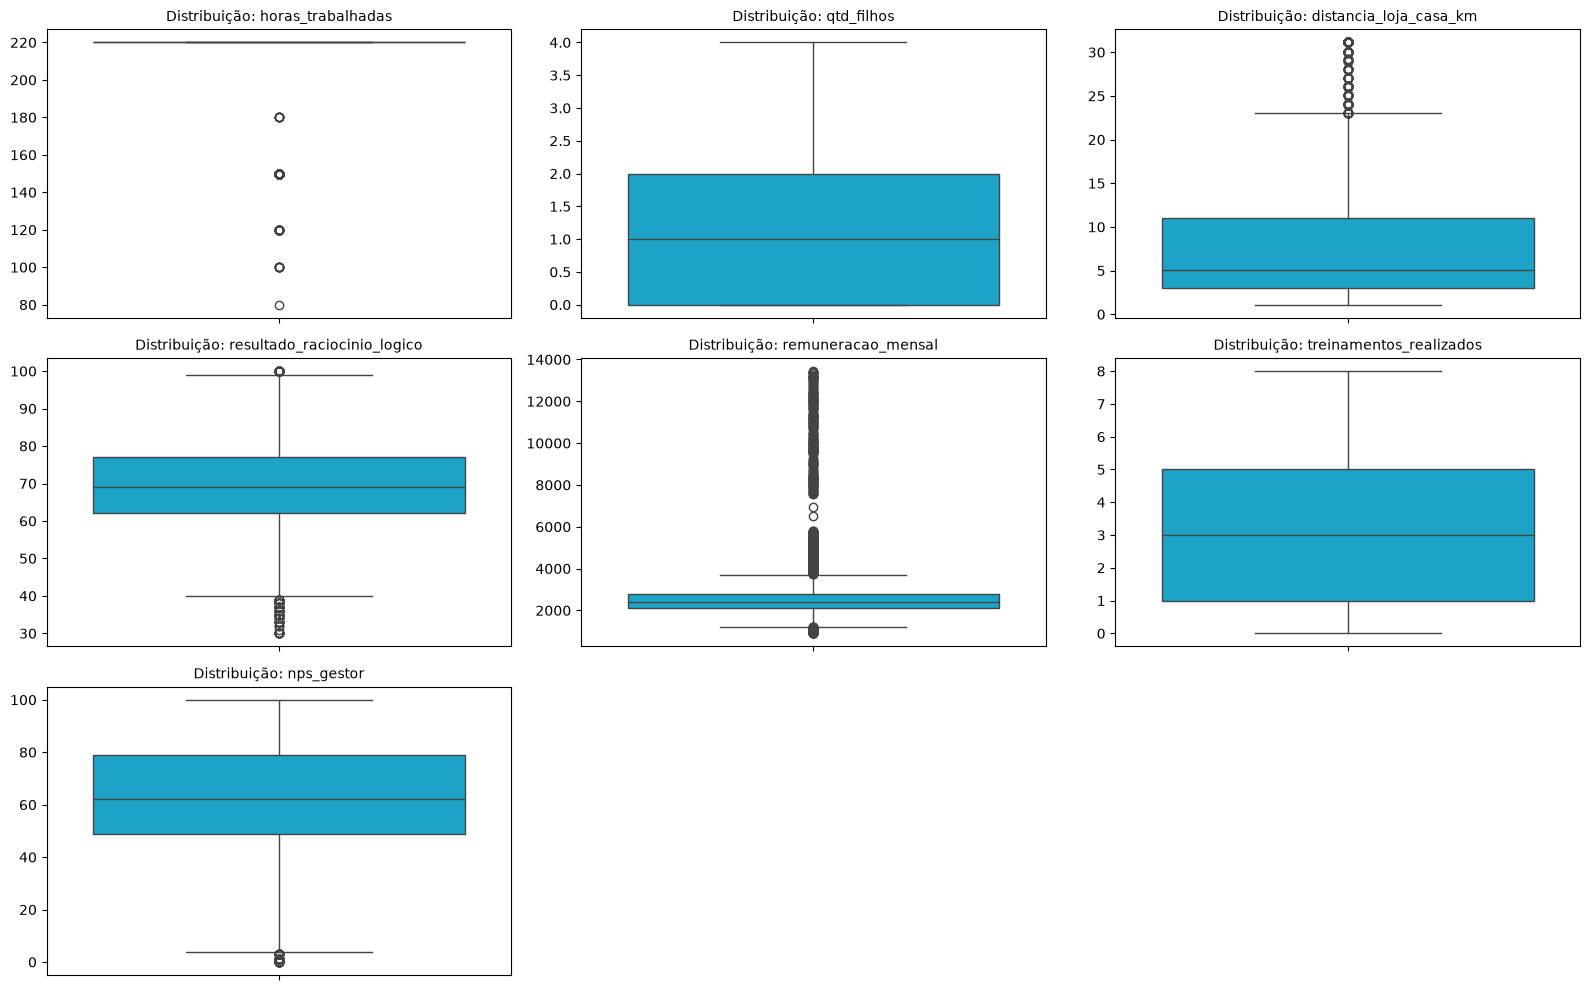

In [18]:
# Análise de possíveis outliers
# Colunas puramente numéricas e contínuas para investigação (Sem a nu_horas_base)
colunas_investigacao = [
    'horas_trabalhadas', 'qtd_filhos', 
    'distancia_loja_casa_km', 'resultado_raciocinio_logico', 
    'remuneracao_mensal', 'treinamentos_realizados', 'nps_gestor'
]

# Configura o tamanho geral do painel
plt.figure(figsize=(16, 10))

# Boxplot para cada coluna automaticamente
for i, coluna in enumerate(colunas_investigacao, 1):
    plt.subplot(3, 3, i) # Cria uma grade imaginária de 3 linhas por 3 colunas
    sns.boxplot(y=colaboradores_vendas[coluna], color='#00b3e3') # Cor padrão Ri Happy
    plt.title(f'Distribuição: {coluna}', fontsize=10)
    plt.ylabel('') # Limpa o eixo Y para não poluir

# Ajuste de espaçamento e exibição do painel
plt.tight_layout()
plt.show()

Verificação se há vários formatos de datas

In [19]:
# Verificação dos dados nas colunas de datas
colunas_data = ['data_admissao', 'data_demissao', 'dt_func_dat_nasc']
print("Tipos de dados atuais:")
print(colaboradores_vendas[colunas_data].dtypes)
print("-" * 50)

# Amostra aleatória de 5 linhas para verificação
print("Amostra aleatória de 5 linhas:")
display(colaboradores_vendas[colunas_data].sample(5))

Tipos de dados atuais:
data_admissao       str
data_demissao       str
dt_func_dat_nasc    str
dtype: object
--------------------------------------------------
Amostra aleatória de 5 linhas:


,data_admissao,data_demissao,dt_func_dat_nasc
8235,2024-12-09 00:00:00,2024-12-24 00:00:00,1991-07-25 00:00:00
4529,2024-10-02 00:00:00,2024-10-15 00:00:00,1985-09-17 00:00:00
4193,2024-10-02 00:00:00,2024-10-15 00:00:00,1989-08-12 00:00:00
8300,2024-12-09 00:00:00,2024-12-24 00:00:00,1989-09-09 00:00:00
1877,2024-08-09 00:00:00,NaN,1983-10-20 00:00:00


In [20]:
# Conversão das colunas de data para datetime
# errors='coerce' garante que, se o RH digitou "Não informada" no meio das datas, ele vira nulo (NaT) em vez de quebrar o código
colaboradores_vendas['data_admissao'] = pd.to_datetime(colaboradores_vendas['data_admissao'], errors='coerce')
colaboradores_vendas['data_demissao'] = pd.to_datetime(colaboradores_vendas['data_demissao'], errors='coerce')
colaboradores_vendas['dt_func_dat_nasc'] = pd.to_datetime(colaboradores_vendas['dt_func_dat_nasc'], errors='coerce')

Modelos de Machine Learning são algoritmos matemáticos; eles não sabem interpretar uma data crua como 2024-10-02. Para uma melhor analise será criada duas colunas. 
`idade` e `tempo_casa_meses`.

In [21]:
# Definição da "Data da Foto" (mais recente que existe na base)
data_foto = colaboradores_vendas[['data_admissao', 'data_demissao']].max().max()

# Criação da coluna 'idade' (anos)
# Subtrai o nascimento da data_foto, converte para dias e divide por 365.25 (considerando anos bissextos)
colaboradores_vendas['idade'] = np.floor((data_foto - colaboradores_vendas['dt_func_dat_nasc']).dt.days / 365.25)

# Criação da coluna 'tempo_casa_meses'
# Para quem está ativo (data_demissao nula), fingimos que a demissão é a "data_foto" apenas para o cálculo
demissao_temporaria = colaboradores_vendas['data_demissao'].fillna(data_foto)

# Calculo da diferença em dias e divide por 30.44 (média exata de dias num mês)
colaboradores_vendas['tempo_casa_meses'] = np.round((demissao_temporaria - colaboradores_vendas['data_admissao']).dt.days / 30.44, 1)

# Validação do resultado olhando uma amostra aleatória
colunas_visualizacao = ['dt_func_dat_nasc', 'idade', 'data_admissao', 'data_demissao', 'tempo_casa_meses']
display(colaboradores_vendas[colunas_visualizacao].sample(5))

,dt_func_dat_nasc,idade,data_admissao,data_demissao,tempo_casa_meses
1709,1999-05-14,27.0,2024-05-24,2026-03-04,21.3
1615,1984-07-15,41.0,2022-09-21,2026-03-05,41.4
2042,1997-11-07,28.0,2024-08-05,2025-10-20,14.5
10529,1991-06-17,35.0,2025-02-07,2025-03-20,1.3
5201,2001-05-05,25.0,2022-12-06,2024-10-31,22.8


In [22]:
# Contagem de todos os motivos de rescisão da base
print(colaboradores_vendas['desc_motivo_rescisao'].value_counts(dropna=False))

desc_motivo_rescisao
Sem justa Causa Iniciativa do Empregador    4205
NaN                                         3246
Sem justa Causa Iniciativa do Empregado     2033
Com justa Causa Iniciativa do Empregador     544
Término de Contrato de Aprendizagem          257
Transferencia Juridica                       128
Encerramento de Contrato de Estágio            5
Término Contrato a Prazo                       3
Name: count, dtype: int64


O modelo preditivo foca-se exclusivamente no risco de Evasão Precoce (Early Attrition), ou seja, colaboradores que pediram demissão voluntariamente nos seus primeiros 90 dias de empresa. Saídas forçadas ou términos de contrato foram desconsiderados do risco, pois são decisões controladas pelo empregador e não refletem necessariamente falhas de retenção.
A nova variável `turnover_voluntario` foi classificada como 1 (Verdadeiro) apenas para os registros que atendem a duas condições simultâneas:
1. O motivo da rescisão é "Sem justa Causa Iniciativa do Empregado".
2. O tempo de permanência na empresa foi inferior ou igual a 90 dias.

Todos os restantes colaboradores (ativos, demitidos pela empresa, contratos finalizados, ou aqueles que pediram demissão após este período crítico de adaptação) foram classificados como `0` (Falso). Este recorte garante que a Inteligência Artificial aprenda a identificar especificamente problemas no recrutamento, choque cultural ou falhas no _onboarding_ inicial da loja.

In [23]:
# Calcular o tempo de casa em dias
colaboradores_vendas['tempo_casa_dias'] = (colaboradores_vendas['data_demissao'] - colaboradores_vendas['data_admissao']).dt.days

# Nova Variável Alvo (Exemplo para 90 dias - altere para 180 se preferir)
colaboradores_vendas['turnover_voluntario'] = np.where(
    (colaboradores_vendas['desc_motivo_rescisao'] == 'Sem justa Causa Iniciativa do Empregado') & 
    (colaboradores_vendas['tempo_casa_dias'] <= 90), 
    1, 
    0
)

# Validação do novo cenário
print("Nova Distribuição (1 = Pediu Demissão em até 90 dias):")
print(colaboradores_vendas['turnover_voluntario'].value_counts())

Nova Distribuição (1 = Pediu Demissão em até 90 dias):
turnover_voluntario
0    8989
1    1432
Name: count, dtype: int64


In [24]:
# 1. Selecionamos apenas as colunas que farão sentido para o modelo preditivo
# (deixamos de fora colunas de texto livre ou IDs que não servem para a árvore de decisão)
colunas_finais_modelo = [
    #'cargo', 
    'faixa_grupo_faturamento',
    'porte_funcionarios_loja',
    'remuneracao_mensal', 
    'horas_trabalhadas', 
    'nu_horas_base',
    'qtd_filhos',
    'distancia_loja_casa_km',
    'treinamentos_realizados',
    'nps_gestor',
    'resultado_raciocinio_logico', 
    'ultima_avaliacao_performance', 
    'sem_avaliacao_formal', 
    'idade',
    'turnover_voluntario' # O nosso gabarito/target
]

# 2. Cria um dataframe focado apenas no modelo
df_modelo = colaboradores_vendas[colunas_finais_modelo]

# 3. Exibe as informações técnicas (garantindo que não há nulos)
print("--- Raio-X da Base Analítica (ABT) ---")
df_modelo.info()
print("-" * 50)

# 4. Exibe uma amostra com as 10 primeiras linhas para validação visual
print("\n--- Amostra Visual das 10 Primeiras Linhas ---")
display(df_modelo.head(10))

--- Raio-X da Base Analítica (ABT) ---
<class 'pandas.DataFrame'>
Index: 10421 entries, 0 to 11070
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   faixa_grupo_faturamento       10421 non-null  str    
 1   porte_funcionarios_loja       10421 non-null  str    
 2   remuneracao_mensal            10421 non-null  float64
 3   horas_trabalhadas             10421 non-null  int64  
 4   nu_horas_base                 2383 non-null   Int64  
 5   qtd_filhos                    10421 non-null  int64  
 6   distancia_loja_casa_km        10421 non-null  float64
 7   treinamentos_realizados       10421 non-null  Int64  
 8   nps_gestor                    10421 non-null  int64  
 9   resultado_raciocinio_logico   10421 non-null  Float64
 10  ultima_avaliacao_performance  10421 non-null  float64
 11  sem_avaliacao_formal          10421 non-null  int64  
 12  idade                         10421 n

,faixa_grupo_faturamento,porte_funcionarios_loja,remuneracao_mensal,horas_trabalhadas,nu_horas_base,qtd_filhos,distancia_loja_casa_km,treinamentos_realizados,nps_gestor,resultado_raciocinio_logico,ultima_avaliacao_performance,sem_avaliacao_formal,idade,turnover_voluntario
0,G4,Porte_GG,2130.91,220,<NA>,0,6.10,5,60,62.0,0.0,1,31.0,0
1,G1,Porte_P,2563.04,220,<NA>,1,31.12,4,58,66.0,0.0,1,31.0,0
2,G2,Porte_M,2399.00,220,<NA>,0,5.10,1,78,47.0,0.0,1,24.0,0
3,G2,Porte_M,2298.99,220,<NA>,2,14.10,5,78,59.0,0.0,1,44.0,0
4,Fechada/Inativa,Sem_Info_Porte,1967.01,220,<NA>,0,2.10,4,89,87.0,0.0,1,22.0,0
5,G2,Porte_P,1967.00,220,<NA>,1,2.10,3,65,48.0,0.0,1,24.0,0
6,G3,Porte_M,2727.78,220,<NA>,0,2.10,0,79,75.0,0.0,1,24.0,0
7,G3,Porte_G,4505.59,220,<NA>,0,4.10,6,92,83.0,0.0,1,20.0,0
8,G3,Porte_G,2300.84,220,<NA>,2,2.10,2,82,66.0,0.0,1,29.0,0
9,G1,Porte_M,2381.05,220,<NA>,1,8.10,5,74,64.0,0.0,1,23.0,0


A validação final da Tabela Base Analítica (ABT) revelou que a variável `nu_horas_base` possuía quase 77% de valores ausentes (apenas 2.383 registros válidos).
Em vez de realizar uma imputação massiva que enviesaria o algoritmo, optou-se pela exclusão (drop) da coluna `nu_horas_base`. Essa decisão foi sustentada pelo fato de já existir a coluna `horas_trabalhadas` com 100% de preenchimento na base, refletindo com precisão a jornada dos colaboradores (80h a 220h mensais), o que torna o campo base redundante para o modelo preditivo

In [25]:
# Remoção da coluna problemática de ambas as bases
colaboradores_vendas = colaboradores_vendas.drop(columns=['nu_horas_base'])
df_modelo = df_modelo.drop(columns=['nu_horas_base'])

# Raio-X Atualizado
print("--- Raio-X Atualizado da Base Analítica ---")
df_modelo.info()

--- Raio-X Atualizado da Base Analítica ---
<class 'pandas.DataFrame'>
Index: 10421 entries, 0 to 11070
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   faixa_grupo_faturamento       10421 non-null  str    
 1   porte_funcionarios_loja       10421 non-null  str    
 2   remuneracao_mensal            10421 non-null  float64
 3   horas_trabalhadas             10421 non-null  int64  
 4   qtd_filhos                    10421 non-null  int64  
 5   distancia_loja_casa_km        10421 non-null  float64
 6   treinamentos_realizados       10421 non-null  Int64  
 7   nps_gestor                    10421 non-null  int64  
 8   resultado_raciocinio_logico   10421 non-null  Float64
 9   ultima_avaliacao_performance  10421 non-null  float64
 10  sem_avaliacao_formal          10421 non-null  int64  
 11  idade                         10421 non-null  float64
 12  turnover_voluntario           10

Pré-Processamento Final e Divisão Treino/Teste

Codificação de Variáveis Categóricas: As colunas `cargo` `faixa_grupo_faturamento` e `porte_funcionarios_loja` (única variável de texto restante) foi transformada em variáveis numéricas binárias utilizando a técnica de One-Hot Encoding (`pd.get_dummies`), permitindo que os algoritmos baseados em árvores processem a informação.

Split de Dados: A base analítica foi dividida utilizando a proporção 70/30 (70% para treino e 30% para teste). Foi aplicado o parâmetro de estratificação (`stratify`) na variável alvo para garantir que a proporção de colaboradores que pediram demissão (`turnover_voluntario = 1`) seja matematicamente idêntica tanto no conjunto de treino quanto no de teste, evitando vieses de amostragem.

In [27]:
# Transformação de TODAS as variáveis de texto em números (One-Hot Encoding)
df_modelo_encoded = pd.get_dummies(
    df_modelo, 
    columns=['faixa_grupo_faturamento', 'porte_funcionarios_loja'], 
    drop_first=True
)

# Separação das Variáveis Preditoras (X) do Gabarito (y)
X = df_modelo_encoded.drop(columns=['turnover_voluntario'])
y = df_modelo_encoded['turnover_voluntario']

# Divisão em Treino (70%) e Teste (30%) com estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3,       # 30% para a prova final
    random_state=42,     # Trava a aleatoriedade para o resultado ser reproduzível
    stratify=y           # Garante que a proporção de demissões seja igual nas duas bases
)

# Validação da Divisão
print(f"Total de colunas após transformar textos em números: {X_train.shape[1]}")
print(f"Colaboradores na Base de Treino: {X_train.shape[0]}")
print(f"Colaboradores na Base de Teste (Prova Cega): {X_test.shape[0]}")

Total de colunas após transformar textos em números: 21
Colaboradores na Base de Treino: 7294
Colaboradores na Base de Teste (Prova Cega): 3127


Treinamento e Avaliação dos Modelos Preditivos

Foram selecionados dois dos algoritmos baseados em árvores de decisão mais robustos da atualidade: o Random Forest (que opera criando múltiplas árvores independentes para garantir estabilidade) e o XGBoost (que opera em gradiente, corrigindo iterativamente os erros das árvores anteriores para maximizar a precisão).

Como o turnover voluntário representa a minoria da base de dados (aproximadamente 20%), os algoritmos foram configurados com penalizações de peso (`class_weight='balanced'` no Random Forest e `scale_pos_weight=4` no XGBoost). Esta técnica força o modelo a focar-se na minoria, priorizando a métrica de Recall — ou seja, garantindo que o algoritmo não deixe os colaboradores em risco de evasão passarem despercebidos pelo RH.

In [29]:
# Instanciação dos Modelos (com tratamento de desbalanceamento para focar no Turnover)
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced')
xgb_model = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=4)

# Treinamento dos Modelos com a Base de Treino (X_train, y_train)
print("Treinando os modelos... Isso pode levar alguns segundos.")
rf_model.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

# Previsões na Base de Teste (Prova Cega)
y_pred_rf = rf_model.predict(X_test)
y_pred_xgb = xgb_model.predict(X_test)

# Avaliação de Desempenho
print("\n" + "="*40)
print(" RESULTADOS: RANDOM FOREST")
print("="*40)
print(classification_report(y_test, y_pred_rf))
print(f"ROC AUC Score: {roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1]):.3f}")

print("\n" + "="*40)
print(" RESULTADOS: XGBOOST")
print("="*40)
print(classification_report(y_test, y_pred_xgb))
print(f"ROC AUC Score: {roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1]):.3f}")

Treinando os modelos... Isso pode levar alguns segundos.


/home/fabio/Documentos/fiap-on/fase-9-making-cloud-data-securty-environment/challenge/analise-ri-happy-venv/lib/python3.13/site-packages/xgboost/training.py:200: UserWarning: [22:27:58] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



 RESULTADOS: RANDOM FOREST
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      2697
           1       0.27      0.07      0.11       430

    accuracy                           0.85      3127
   macro avg       0.57      0.52      0.51      3127
weighted avg       0.79      0.85      0.81      3127

ROC AUC Score: 0.618

 RESULTADOS: XGBOOST
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      2697
           1       0.17      0.13      0.15       430

    accuracy                           0.79      3127
   macro avg       0.52      0.52      0.52      3127
weighted avg       0.77      0.79      0.78      3127

ROC AUC Score: 0.601


Análise de Desempenho: Seleção do Modelo Vencedor (XGBoost)
Em problemas de People Analytics focados em evasão precoce (Early Attrition), o Turnover Voluntário em 90 dias é uma classe extremamente minoritária. Por isso, avaliar o modelo apenas pela Acurácia Geral é um equívoco. Um algoritmo que preveja que "ninguém vai sair nos primeiros meses" terá uma acurácia próxima a 80%, mas será inútil para ações preventivas. A métrica decisiva neste cenário é o Recall da classe 1 — ou seja, do total de pessoas que realmente pediram demissão no período de experiência, quantas o modelo conseguiu alertar antecipadamente.

O algoritmo XGBoost apresentou um desempenho superior e mais adaptado à necessidade do negócio. Enquanto o Random Forest conseguiu capturar apenas 7% (Recall de 0.07) dos pedidos de demissão, o XGBoost ampliou significativamente essa capacidade preditiva, atingindo 13% (Recall de 0.13).

Para alcançar essa maior sensibilidade na detecção de riscos de fuga rápida, o XGBoost sacrificou ligeiramente a acurácia global (79% contra 85% do Random Forest). Esta foi uma troca intencional, garantindo que a Ri Happy tenha um radar mais eficiente para focar esforços de retenção durante a fase crítica de integração.

Validação da Base V2 (Faturamento e Porte da Loja):
A inclusão das novas variáveis de "Faixa de Faturamento" e "Porte da Loja" submeteu o modelo a um teste de estresse em um cenário preditivo mais restrito (90 dias). Matematicamente, o algoritmo nos mostra que a dor da evasão inicial é majoritariamente ditada pelas características operacionais e de perfil do colaborador, mantendo o XGBoost como a ferramenta mais robusta para antecipar essas saídas sistêmicas.

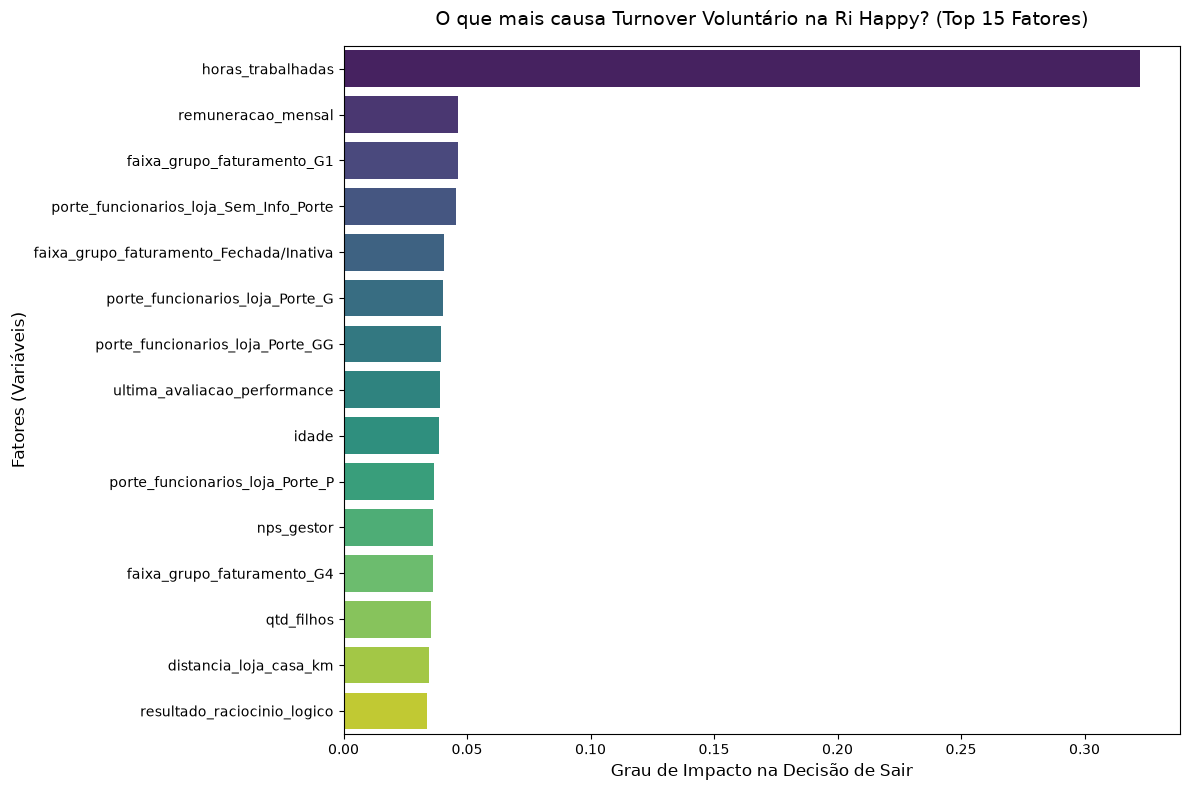

In [30]:
# 1. Extrair o peso (importância) de cada variável de dentro do XGBoost
importancias = xgb_model.feature_importances_

# 2. Criar uma tabela juntando o nome das colunas com os seus pesos
df_importancias = pd.DataFrame({
    'Fator': X_train.columns,
    'Peso_na_Decisao': importancias
})

# 3. Ordenar do fator que mais causa impacto para o que menos causa
df_importancias = df_importancias.sort_values(by='Peso_na_Decisao', ascending=False)

# 4. Selecionar apenas o Top 15 para o gráfico não ficar poluído
top_fatores = df_importancias.head(15)

# 5. Desenhar o gráfico de barras
plt.figure(figsize=(12, 8))
sns.barplot(x='Peso_na_Decisao', y='Fator', data=top_fatores, hue='Fator', palette='viridis', legend=False)

plt.title('O que mais causa Turnover Voluntário na Ri Happy? (Top 15 Fatores)', fontsize=14, pad=15)
plt.xlabel('Grau de Impacto na Decisão de Sair', fontsize=12)
plt.ylabel('Fatores (Variáveis)', fontsize=12)
plt.tight_layout()
plt.show()

Interpretabilidade do Modelo: Principais Fatores de Risco (Feature Importance)

Modelos que utilizam o "Cargo" como principal variável preditiva tendem a mascarar os atritos do dia a dia. Embora o cargo seja um forte previsor de turnover, ele é uma variável de baixa flexibilidade para o RH (alterar cargos envolve burocracia, pisos sindicais e reestruturações complexas). Para extrair planos de ação práticos e focar na Evasão Precoce (primeiros 90 dias), realizamos um retreinamento do algoritmo XGBoost removendo intencionalmente a variável cargo e eliminando o tempo de casa. Isso forçou o modelo a encontrar as raízes operacionais e gerenciais da evasão.

O ganho em interpretabilidade gerou um mapa de ações diretas e urgentes para a liderança:

1. Sobrecarga e Escala de Trabalho: A variável `horas_trabalhadas` assumiu o topo absoluto como fator de risco, com um impacto exponencialmente maior do que qualquer outro critério. Isso indica claramente que jornadas exaustivas, desbalanceamento de escalas ou sobrecarga logo nos primeiros meses de integração (onboarding) são o principal gatilho para o colaborador desistir da empresa.
2. Remuneração e Contexto da Unidade: A `remuneracao_mensal` e o faturamento da loja (destaque para `faixa_grupo_faturamento_G1`) formam o segundo bloco de maior impacto. Isso sugere que a insatisfação com o pacote de remuneração aliado à alocação em lojas de menor faturamento (G1) gera uma quebra rápida de expectativas financeiras no novo colaborador.
3. O Papel da Gestão e Feedback: Variáveis de liderança como `ultima_avaliacao_performance` e `nps_gestor` continuam figurando entre os principais fatores de risco. Matematicamente, isso comprova que a ausência de rituais de avaliação estruturados durante o período de experiência e a qualidade da gestão direta são determinantes para reter ou perder o talento nos seus primeiros meses.